# Portfolio Allocation Project — Part 4: Long-Only Minimum Variance

**Goal:** the minimum-variance portfolio of Parts 2 and 3 relied on large short positions (48%–83% of capital, mostly in TLT). Many investors can't or won't short: pension funds and mutual funds often have rules against it, and shorting requires margin and pays a borrow fee. Here we add the constraint that **every weight must be between 0 and 1**:

$$\min_{\mathbf a} \; \mathbf a^\top \Sigma\, \mathbf a \quad \text{subject to} \quad \sum_k a_k = 1, \quad a_k \ge 0$$

With this constraint there is **no closed-form formula**, so we use a numerical optimizer (`scipy.optimize.minimize`). Then we rerun the rolling backtest of Part 3 and compare three strategies: **long-only minimum variance**, **unconstrained minimum variance** (with shorts) and **1/N**.

**Structure:**

| Section | Content |
|---|---|
| 1–2 | Data and the tools from Parts 2 and 3 |
| 3 | Long-only weights with a numerical optimizer |
| 4 | Comparing both sets of weights on one date |
| 5 | A reusable backtest and the three strategies |
| 6 | Performance metrics (including Sharpe ratios) and growth of $1 |
| 7 | How the long-only weights move, and how concentrated they are |
| 8 | Turnover |
| 9 | Conclusions |

**Inputs:** `returns.csv` from Part 1, and `risk_free.csv` (3-month T-bill rate) from Part 3. If `risk_free.csv` is missing, it is downloaded.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize

TRADING_DAYS = 252
EST_DAYS = 3 * TRADING_DAYS   # same 3-year window as Part 3

## 1. Load the returns and the risk-free rate

The risk-free rate is the 3-month U.S. Treasury bill yield (`^IRX`, annualized, in percent), converted to a daily rate. It is used for the Sharpe ratios in section 6.

In [2]:
returns = pd.read_csv("returns.csv", index_col=0, parse_dates=True)
tickers = list(returns.columns)
K = len(tickers)
print(f"{returns.shape[0]} days x {K} assets, from {returns.index[0].date()} to {returns.index[-1].date()}")

RF_FILE = "risk_free.csv"
if os.path.exists(RF_FILE):
    irx = pd.read_csv(RF_FILE, index_col=0, parse_dates=True).iloc[:, 0]
else:
    raw = yf.download("^IRX", start=returns.index[0], end=returns.index[-1] + pd.Timedelta(days=1),
                      auto_adjust=True, progress=False)
    irx = raw["Close"].iloc[:, 0]
    irx.to_csv(RF_FILE)

# Annualized yield in percent -> daily rate, aligned with the return dates
rf_daily = (irx / 100 / TRADING_DAYS).reindex(returns.index).ffill()

2721 days x 10 assets, from 2016-01-05 to 2026-10-29


## 2. Tools from Parts 2 and 3

The functions and rebalancing dates built in the previous parts, so this notebook runs on its own:

- `min_variance_weights`: the unconstrained closed-form solution (shorts allowed).
- `performance`: annualized return, volatility, return/volatility and maximum drawdown from daily log returns.
- `sharpe_ratio`: return above the risk-free rate per unit of risk, computed on simple returns.
- `portfolio_volatility`: annualized volatility of a portfolio from a daily covariance matrix.
- `estimation_window`: the 756 trading days ending at a rebalance date (no look-ahead).
- `rebalance_dates`: the last trading day of each month with a full 3-year window, from January 2019 to September 2026.

In [3]:
def min_variance_weights(Sigma):
    """Unconstrained minimum-variance weights (shorting allowed)."""
    iota = np.ones(Sigma.shape[0])
    x = np.linalg.solve(Sigma, iota)
    return x / x.sum()


def performance(port_returns):
    """Annualized metrics for a Series of daily portfolio log returns."""
    ann_return = port_returns.mean() * TRADING_DAYS
    ann_volatility = port_returns.std() * np.sqrt(TRADING_DAYS)
    value = np.exp(port_returns.cumsum())
    drawdown = value / value.cummax() - 1
    return pd.Series({
        "ann_return": ann_return,
        "ann_volatility": ann_volatility,
        "return_over_vol": ann_return / ann_volatility,
        "max_drawdown": drawdown.min(),
    })


def sharpe_ratio(log_returns, rf):
    """Annualized Sharpe ratio from daily log returns and a daily risk-free rate."""
    excess = np.exp(log_returns) - 1 - rf
    return excess.mean() / excess.std() * np.sqrt(TRADING_DAYS)


def portfolio_volatility(a, Sigma):
    """Annualized volatility of a portfolio with weights a, from a daily covariance matrix."""
    return np.sqrt(a @ Sigma @ a) * np.sqrt(TRADING_DAYS)


def estimation_window(t):
    """The EST_DAYS rows of returns ending at date t (included)."""
    p = returns.index.get_loc(t)
    return returns.iloc[p - EST_DAYS + 1 : p + 1]


month_ends = returns.index.to_series().groupby(returns.index.to_period("M")).max()
eligible = [t for t in month_ends if returns.index.get_loc(t) >= EST_DAYS - 1]
rebalance_dates = pd.DatetimeIndex(eligible[:-1])
print(f"{len(rebalance_dates)} rebalances, from {rebalance_dates[0].date()} to {rebalance_dates[-1].date()}")

93 rebalances, from 2019-01-31 to 2026-09-30


## 3. Long-only weights with a numerical optimizer

Without shorts, the formula $\Sigma^{-1}\boldsymbol\iota / \boldsymbol\iota^\top\Sigma^{-1}\boldsymbol\iota$ no longer works: it can give negative weights, and simply setting them to zero is **not** the optimal long-only portfolio, because removing one position changes how the others should hedge each other. Instead, an optimizer searches for the weights step by step, always respecting the constraints.

`scipy.optimize.minimize` needs four ingredients:

| Ingredient | What it is here |
|---|---|
| `fun` | The function to minimize: the portfolio variance $\mathbf a^\top\Sigma\,\mathbf a$, as a function of `a` |
| `x0` | A starting point: equal weights are a natural, valid choice |
| `bounds` | One `(min, max)` pair per asset: `(0, 1)` means "no shorts, no more than 100%" |
| `constraints` | The weights must add up to 1. An **equality** constraint is a function that must equal 0: `a.sum() - 1` |

We use `method="SLSQP"` (Sequential Least Squares Programming), which handles both bounds and equality constraints.

**A numerical trap:** daily variances are tiny (around 0.00001). With such small numbers, the optimizer believes it has already reached the minimum at the starting point and stops immediately, silently returning equal weights. To avoid this, we optimize the **annualized** covariance matrix (`Sigma * TRADING_DAYS`). Multiplying by a constant doesn't change which weights are optimal; it only puts the numbers on a scale the optimizer handles well.

In [4]:
def long_only_weights(Sigma):
    """Long-only minimum-variance weights (0 <= a_k <= 1, sum = 1)."""
    n = Sigma.shape[0]
    Sigma_ann = Sigma * TRADING_DAYS   # rescale to avoid the numerical trap

    objective = lambda a: a @ Sigma_ann @ a                     # portfolio variance to minimize
    x0 = np.ones(n) / n                                         # start from equal weights
    bounds = [(0, 1)] * n                                       # no shorts, at most 100% per asset
    constraint = {"type": "eq", "fun": lambda a: a.sum() - 1}   # fully invested

    result = minimize(objective, x0, bounds=bounds, constraints=constraint, method="SLSQP")
    return result.x

**A quick illustration: the hedge example from Part 2.** Two assets with variances 4 and 1 and a correlation of 0.9. The unconstrained formula shorts the volatile asset to hedge the calm one; without shorts, the best the optimizer can do is put everything in the calm asset.

In [5]:
Sigma_example = np.array([[4.0, 1.8],
                          [1.8, 1.0]])
print("Unconstrained:", min_variance_weights(Sigma_example).round(3))
print("Long-only:    ", long_only_weights(Sigma_example).round(3))

Unconstrained: [-0.571  1.571]
Long-only:     [0. 1.]


## 4. Comparing the weights on one date

Before the backtest, we compare both portfolios on the last rebalance date (30 September 2026), using the same 3-year estimation window.

In [6]:
S_real = estimation_window(rebalance_dates[-1]).cov().to_numpy()
a_unc = min_variance_weights(S_real)
a_lo = long_only_weights(S_real)

comparison = pd.DataFrame({
    "unconstrained": a_unc,
    "long_only": a_lo,
}, index=tickers)

for name, a in [("unconstrained", a_unc), ("long_only", a_lo)]:
    print(f"{name:>14}: volatility = {portfolio_volatility(a, S_real):.2%}")

comparison.round(3)

 unconstrained: volatility = 3.59%
     long_only: volatility = 5.88%


,unconstrained,long_only
SPY,0.135,0.054
IWM,-0.036,0.000
EFA,-0.075,0.000
EEM,-0.038,0.000
TLT,-0.612,0.000
IEF,1.042,0.621
LQD,0.474,0.000
EMLC,0.160,0.325
GLD,-0.017,0.000
VNQ,-0.032,0.000


**Reading the weights**

- **The long-only portfolio uses only 3 assets:** IEF (62.1%), EMLC (32.5%) and SPY (5.4%). Every other weight is exactly 0. This is typical of constrained optimization: once a weight hits the lower bound of 0, the optimizer simply drops that asset.
- **The IEF / TLT pair disappears.** Without the 61% TLT short, the optimizer can't hedge interest-rate risk anymore, so IEF falls from 104% to 62% and EMLC takes a large share. LQD (47% unconstrained) disappears completely: its value in the unconstrained portfolio came from combining it with the shorts.
- **The constraint costs volatility:** 5.88% vs 3.59% estimated on this window. By definition, a constrained optimum can never have less variance than the unconstrained one.

## 5. A reusable backtest

In Part 3 the loop called `min_variance_weights` directly. Here we want to run the **same** loop with two different weight functions. In Python a function can be passed as an argument to another function, just like a number or a DataFrame, so `run_backtest(weight_function)` runs the Part 3 loop calling `weight_function(Sigma)` each month.

Each month it estimates $\hat\Sigma$ on the window ending at $t$, computes the weights, holds them from the day after $t$ until the next rebalance, and records the portfolio's daily returns.

In [7]:
def run_backtest(weight_function):
    """Rolling backtest (3-year window, monthly rebalancing) for any weight function.

    Returns (daily returns Series, DataFrame of weights with one row per rebalance date).
    """
    weights_history = {}
    monthly_pieces = []

    for i, t in enumerate(rebalance_dates):
        a = weight_function(estimation_window(t).cov().to_numpy())   # weights using data up to t
        weights_history[t] = a
        hold_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else returns.index[-1]
        hold = returns.loc[(returns.index > t) & (returns.index <= hold_end)]
        monthly_pieces.append(hold @ a)                             # portfolio returns for the month

    weights = pd.DataFrame(weights_history, index=tickers).T
    return pd.concat(monthly_pieces), weights

We run the backtest with both weight functions. As a consistency check, the unconstrained run reproduces Part 3 exactly (1,947 days, 4.77% volatility, 2.46% return). 1/N is computed on the same days.

In [8]:
mv_returns, weights_mv = run_backtest(min_variance_weights)
lo_returns, weights_lo = run_backtest(long_only_weights)

a_ew = np.ones(K) / K
ew_returns = returns.loc[lo_returns.index] @ a_ew

backtest = pd.DataFrame({
    "long_only": lo_returns,
    "min_variance": mv_returns,
    "equal_weight": ew_returns,
})
rf_bt = rf_daily.loc[backtest.index]
print(f"Out-of-sample: {backtest.index[0].date()} to {backtest.index[-1].date()}  ({len(backtest)} days)")

Out-of-sample: 2019-02-01 to 2026-10-29  (1947 days)


## 6. Results: metrics and growth of $1

In [9]:
results = pd.DataFrame({name: performance(backtest[name]) for name in backtest})
results.loc["sharpe_ratio"] = [sharpe_ratio(backtest[name], rf_bt) for name in backtest]
results.round(4)

,long_only,min_variance,equal_weight
ann_return,0.0229,0.0246,0.0625
ann_volatility,0.0689,0.0477,0.1164
return_over_vol,0.3317,0.5150,0.5366
max_drawdown,-0.1994,-0.1368,-0.2494
sharpe_ratio,-0.0327,-0.0374,0.3597


**Reading the table**

- **Risk sits in between, closer to minimum variance:** long-only has 6.9% volatility, compared with 4.8% for unconstrained minimum variance and 11.6% for 1/N. Removing the shorts costs about 2 percentage points of volatility, but the portfolio is still much less risky than 1/N.
- **Return is about the same as with shorts:** 2.29% vs 2.46%. The shorts reduced risk, not return.
- **Sharpe ratio:** both minimum-variance versions are slightly negative (−0.03 and −0.04) because their returns were below the T-bill rate (2.75% on average), while 1/N had 0.36. Removing the shorts does not fix the main weakness found in Part 3.
- **Drawdown is where long-only loses most:** −19.9%, versus −13.7% with shorts (and −24.9% for 1/N).

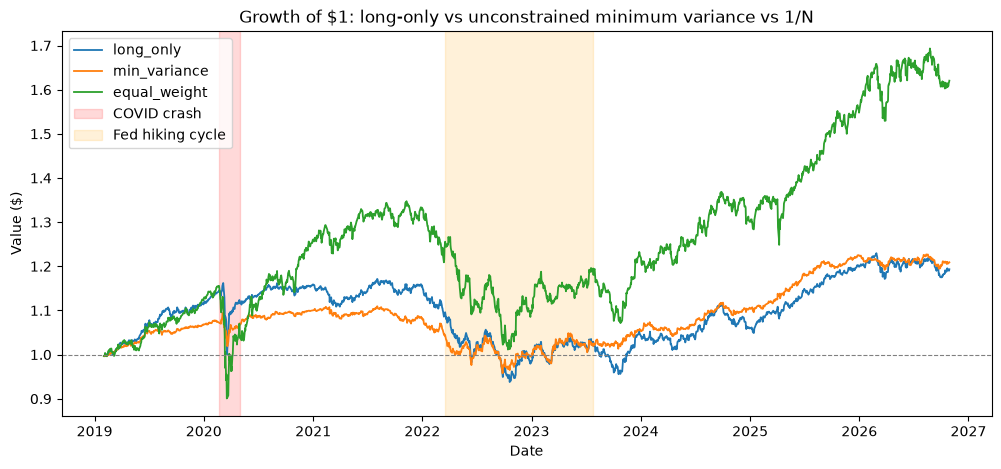

In [10]:
growth = np.exp(backtest.cumsum())

fig, ax = plt.subplots(figsize=(12, 5))
for name in growth.columns:
    ax.plot(growth.index, growth[name], label=name, linewidth=1.3)
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")

ax.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30"),
           color="red", alpha=0.15, label="COVID crash")
ax.axvspan(pd.Timestamp("2022-03-16"), pd.Timestamp("2023-07-26"),
           color="orange", alpha=0.15, label="Fed hiking cycle")

ax.set_title("Growth of $1: long-only vs unconstrained minimum variance vs 1/N")
ax.set_xlabel("Date")
ax.set_ylabel("Value ($)")
ax.legend()
plt.show()

**Reading the chart**

- **Until early 2022, long-only was ahead of the unconstrained version.** Without the TLT short, it benefited fully from the bond rally of 2019–2020 (+10.8% in 2019 vs +6.5%).
- **COVID crash:** both minimum-variance versions held up well (about −2% for long-only and −0.2% for unconstrained, against −9% for 1/N over the crash window).
- **2022 is where the short mattered:** long-only lost 16.3% in 2022, twice as much as the unconstrained version (−8.0%) and close to 1/N (−19.7%). In the unconstrained portfolio, the TLT short gained as long Treasuries crashed and offset part of the losses on IEF; without it, the long-only portfolio was fully exposed to rising rates.
- **Both minimum-variance versions end close together:** $1.19 for long-only and $1.21 with shorts, against $1.62 for 1/N.

## 7. How the long-only weights move over time

Long-only weights are all positive and add up to 1, so a **stacked area chart** shows the whole portfolio at once: each band is one asset's share of the money.

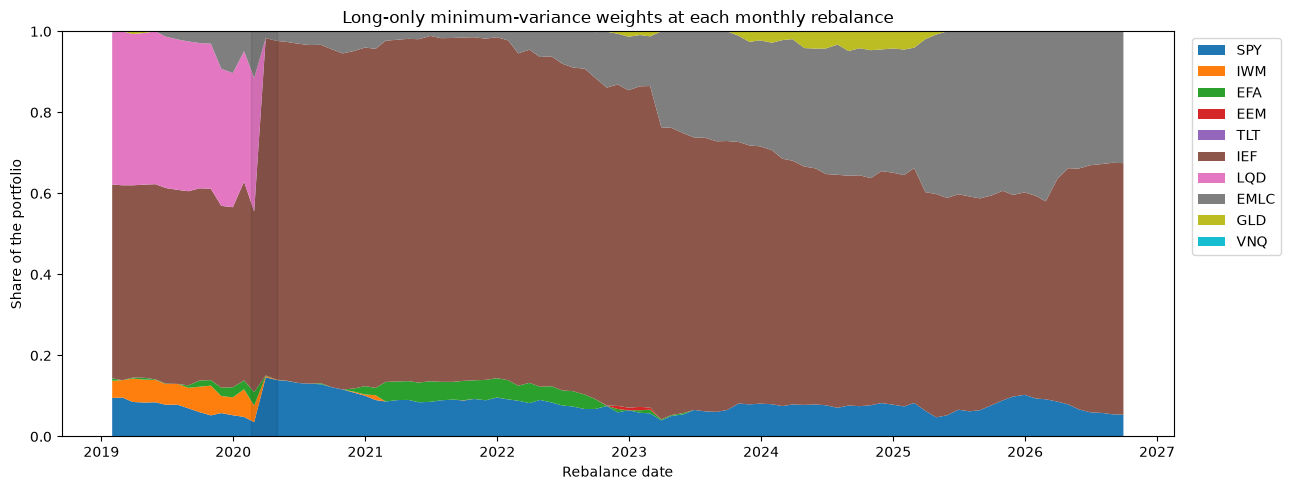

In [11]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.stackplot(weights_lo.index, weights_lo.T.values, labels=tickers)
ax.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30"), color="black", alpha=0.08)
ax.set_title("Long-only minimum-variance weights at each monthly rebalance")
ax.set_xlabel("Rebalance date")
ax.set_ylabel("Share of the portfolio")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [12]:
n_assets = (weights_lo > 0.01).sum(axis=1)   # assets with more than 1% of the portfolio

print(f"Assets held (weight > 1%): average {n_assets.mean():.1f}, minimum {n_assets.min()}, maximum {n_assets.max()}")
print()
print("Weight range of each asset over the backtest:")
weights_lo.agg(["min", "mean", "max"]).T.round(3)

Assets held (weight > 1%): average 3.8, minimum 3, maximum 6

Weight range of each asset over the backtest:


,min,mean,max
SPY,0.035,0.080,0.146
IWM,0.000,0.008,0.073
EFA,0.000,0.012,0.051
EEM,0.000,0.000,0.008
TLT,0.000,0.000,0.000
IEF,0.444,0.663,0.852
LQD,0.000,0.054,0.380
EMLC,0.000,0.175,0.420
GLD,0.000,0.007,0.049
VNQ,0.000,0.000,0.000


**Reading the weights**

- **A concentrated portfolio:** on average it holds only about 4 assets with more than 1% each (between 3 and 6). TLT, VNQ and EEM never receive a meaningful weight.
- **IEF is the core:** between 44% and 85% (66% on average). Without shorts, the lowest-volatility asset becomes the anchor of the portfolio.
- **The COVID crash reshapes the portfolio.** LQD had up to 38% before March 2020 and is dropped once the crash enters the estimation window, while IEF rises to about 85%. From 2023, as the crash leaves the window, EMLC grows to as much as 42%.
- **Equities stay small:** SPY between 3.5% and 15%, with small, occasional positions in IWM, EFA and GLD.

## 8. Turnover

Same definition as Part 3: at each rebalance, $\text{turnover}_t = \sum_k |a_{k,t} - a_{k,t-1}|$, the share of capital traded.

In [13]:
turnover = pd.DataFrame({
    "long_only": weights_lo.diff().abs().sum(axis=1).iloc[1:],
    "min_variance": weights_mv.diff().abs().sum(axis=1).iloc[1:],
})

summary = pd.DataFrame({
    "avg_monthly": turnover.mean(),
    "median_monthly": turnover.median(),
    "annual": turnover.mean() * 12,
})
print(summary.round(3))
print()
print("Largest long-only rebalances:")
print(turnover["long_only"].sort_values(ascending=False).head(4).round(3))

              avg_monthly  median_monthly  annual
long_only           0.045           0.024   0.545
min_variance        0.066           0.044   0.791

Largest long-only rebalances:
2020-03-31    0.995
2023-03-31    0.228
2020-02-28    0.171
2025-03-31    0.161
Name: long_only, dtype: float64


**Reading the turnover**

- **Long-only trades less:** about 55% of capital per year, against 79% for the unconstrained version, and the median month trades only 2.4% (vs 4.4%). With no shorts, gross exposure is only 100% instead of about 230%, so there is simply less to rebalance.
- **But its biggest rebalance is bigger:** in March 2020 the long-only portfolio traded almost 100% of its capital, when the COVID crash entered the window and the optimizer moved out of LQD and into IEF in one step. Corner solutions (weights at exactly 0) can jump when an asset enters or leaves the portfolio.
- **Costs remain negligible:** at 5 basis points per dollar traded, 55% annual turnover costs less than 0.03% per year.

## 9. Conclusions

1. **The cost of the constraint.** Removing the short positions raised volatility from 4.8% to 6.9%, but the long-only portfolio is still much less risky than 1/N (11.6%). The constrained optimizer produces a concentrated portfolio of about 4 assets, anchored on IEF (66% on average).

2. **Return and efficiency.** Long-only earned about the same as the unconstrained version (2.3% vs 2.5% per year; $1 became $1.19 vs $1.21), and both had slightly negative Sharpe ratios (−0.03 and −0.04) against 0.36 for 1/N. Removing the shorts makes the strategy more practical, but not more efficient.

3. **What the shorts were doing.** The long IEF / short TLT pair hedged interest-rate risk. Without it, the long-only portfolio is a plain bond-heavy portfolio: it did better in the bond rally of 2019–2020, but lost twice as much in 2022 (−16.3% vs −8.0%) and had a deeper worst fall (−19.9% vs −13.7%).

4. **Turnover.** Long-only trades less overall (55% vs 79% per year), although its weights can jump sharply when the optimizer moves an asset in or out, as in March 2020. Trading costs remain negligible.

**Overall:** across Parts 3 and 4, minimum variance reliably delivers lower risk than 1/N, with or without shorts. In this sample, which was a difficult period for Treasuries, that lower risk came with returns below the T-bill rate, so 1/N was the more efficient choice. The long-only version is the more realistic implementation, at the cost of more exposure to rising rates.

**Possible extensions:** cap the maximum weight per asset (for example 40%) to force more diversification; compare EWMA or Ledoit-Wolf covariance estimates; or add assets that hedge inflation shocks, such as short-term T-bills or TIPS, as discussed in Part 1.